# Notebook 05: Cross-Validation Statistical Methodology and Hypothesis Testing

## Rigorous Statistical Protocol for 5-Fold Cross-Validation
Standard independent hypothesis tests (such as Student's paired $t$-test or naive Wilcoxon signed-rank tests) violate the independence assumption when applied to $K$-fold cross-validation because training sets across folds overlap ($K-1$ folds share data), leading to artificially deflated variance and inflated Type I error rates.

To ensure statistical rigor, this notebook presents hypothesis testing using five complementary paradigms:
1. **Omnibus Non-Parametric Friedman Test**: Tests whether all architectures within a track perform identically across the 5 folds.
2. **Kendall's $W$ (Coefficient of Concordance)**: Quantifies inter-fold ranking agreement ($0 = \text{no agreement}$, $1 = \text{unanimous ranking}$).
3. **Nadeau–Bengio Corrected Paired $t$-Test**:
   $$\hat{\sigma}_{\text{corrected}}^2 = \left(\frac{1}{K} + \frac{n_{\text{test}}}{n_{\text{train}}}\right) s^2, \quad t = \frac{\bar{d}}{\hat{\sigma}_{\text{corrected}}}$$
   with $K=5$, correcting degrees of freedom and variance for cross-validation overlap.
4. **Wilcoxon Signed-Rank Test with Sample Size Limitation**:
   > [!NOTE]
   > For $n=5$ folds, the minimum possible two-sided non-parametric Wilcoxon $p$-value is $2 \times (1/2)^5 = 0.0625 > 0.05$. Therefore, exact Wilcoxon tests cannot detect significance at $\alpha=0.05$ with 5 folds alone; reported for transparency alongside asymptotic values.
5. **Pooled Out-of-Fold (OOF) McNemar's Test**: Sample-level paired contingency test with Edward's continuity correction on independent outer predictions ($N_{\text{fundus}}=1,367$, $N_{\text{oct}}=1,140$, $N_{\text{seq}}=146$, $N_{\text{sev}}=895$).
6. **Holm–Bonferroni Step-Down Correction**: Controls Family-Wise Error Rate (FWER) across all pairwise hypothesis comparisons.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML, Image

PROJECT_ROOT = Path("..").resolve()
STATS_DIR = PROJECT_ROOT / "results" / "cross_validation" / "statistical_analysis"
FIG_DIR = STATS_DIR / "figures"
print(f"Loading statistical artifacts from: {STATS_DIR}")


Loading statistical artifacts from: C:\Users\Shuvendu\Desktop\Papilledema_analysis\results\cross_validation\statistical_analysis


## 1. Omnibus Hypothesis Testing: Friedman Test & Kendall's $W$

Evaluating whether architectural performance differences across the 5 folds are statistically significant across four primary evaluation metrics.


track,metric,n_models,n_folds,friedman_chi2,p_value,kendalls_w,significant_unadj,caveat,p_adjusted_holm,significant_holm
fundus_3class,macro_f1,10,5,38.323636,0.000015,0.851636,True,5 CV folds share overlapping ~75% training subsets; treat as fold-level block omnibus.,0.000046,True
fundus_3class,balanced_accuracy,10,5,36.970909,0.000027,0.821576,True,5 CV folds share overlapping ~75% training subsets; treat as fold-level block omnibus.,0.000080,True
fundus_3class,macro_recall,10,5,36.970909,0.000027,0.821576,True,5 CV folds share overlapping ~75% training subsets; treat as fold-level block omnibus.,0.000080,True
fundus_3class,macro_precision,10,5,37.320000,0.000023,0.829333,True,5 CV folds share overlapping ~75% training subsets; treat as fold-level block omnibus.,0.000092,True
fundus_3class,weighted_f1,10,5,37.494545,0.000021,0.833212,True,5 CV folds share overlapping ~75% training subsets; treat as fold-level block omnibus.,0.000086,True
oct_individual,macro_f1,10,5,40.351899,0.000007,0.896709,True,5 CV folds share overlapping ~75% training subsets; treat as fold-level block omnibus.,0.000026,True
oct_individual,balanced_accuracy,10,5,38.201521,0.000016,0.848923,True,5 CV folds share overlapping ~75% training subsets; treat as fold-level block omnibus.,0.000064,True
oct_individual,macro_recall,10,5,38.201521,0.000016,0.848923,True,5 CV folds share overlapping ~75% training subsets; treat as fold-level block omnibus.,0.000064,True
oct_individual,macro_precision,10,5,29.870886,0.000461,0.663797,True,5 CV folds share overlapping ~75% training subsets; treat as fold-level block omnibus.,0.000923,True
oct_individual,weighted_f1,10,5,35.065823,0.000058,0.779241,True,5 CV folds share overlapping ~75% training subsets; treat as fold-level block omnibus.,0.000174,True


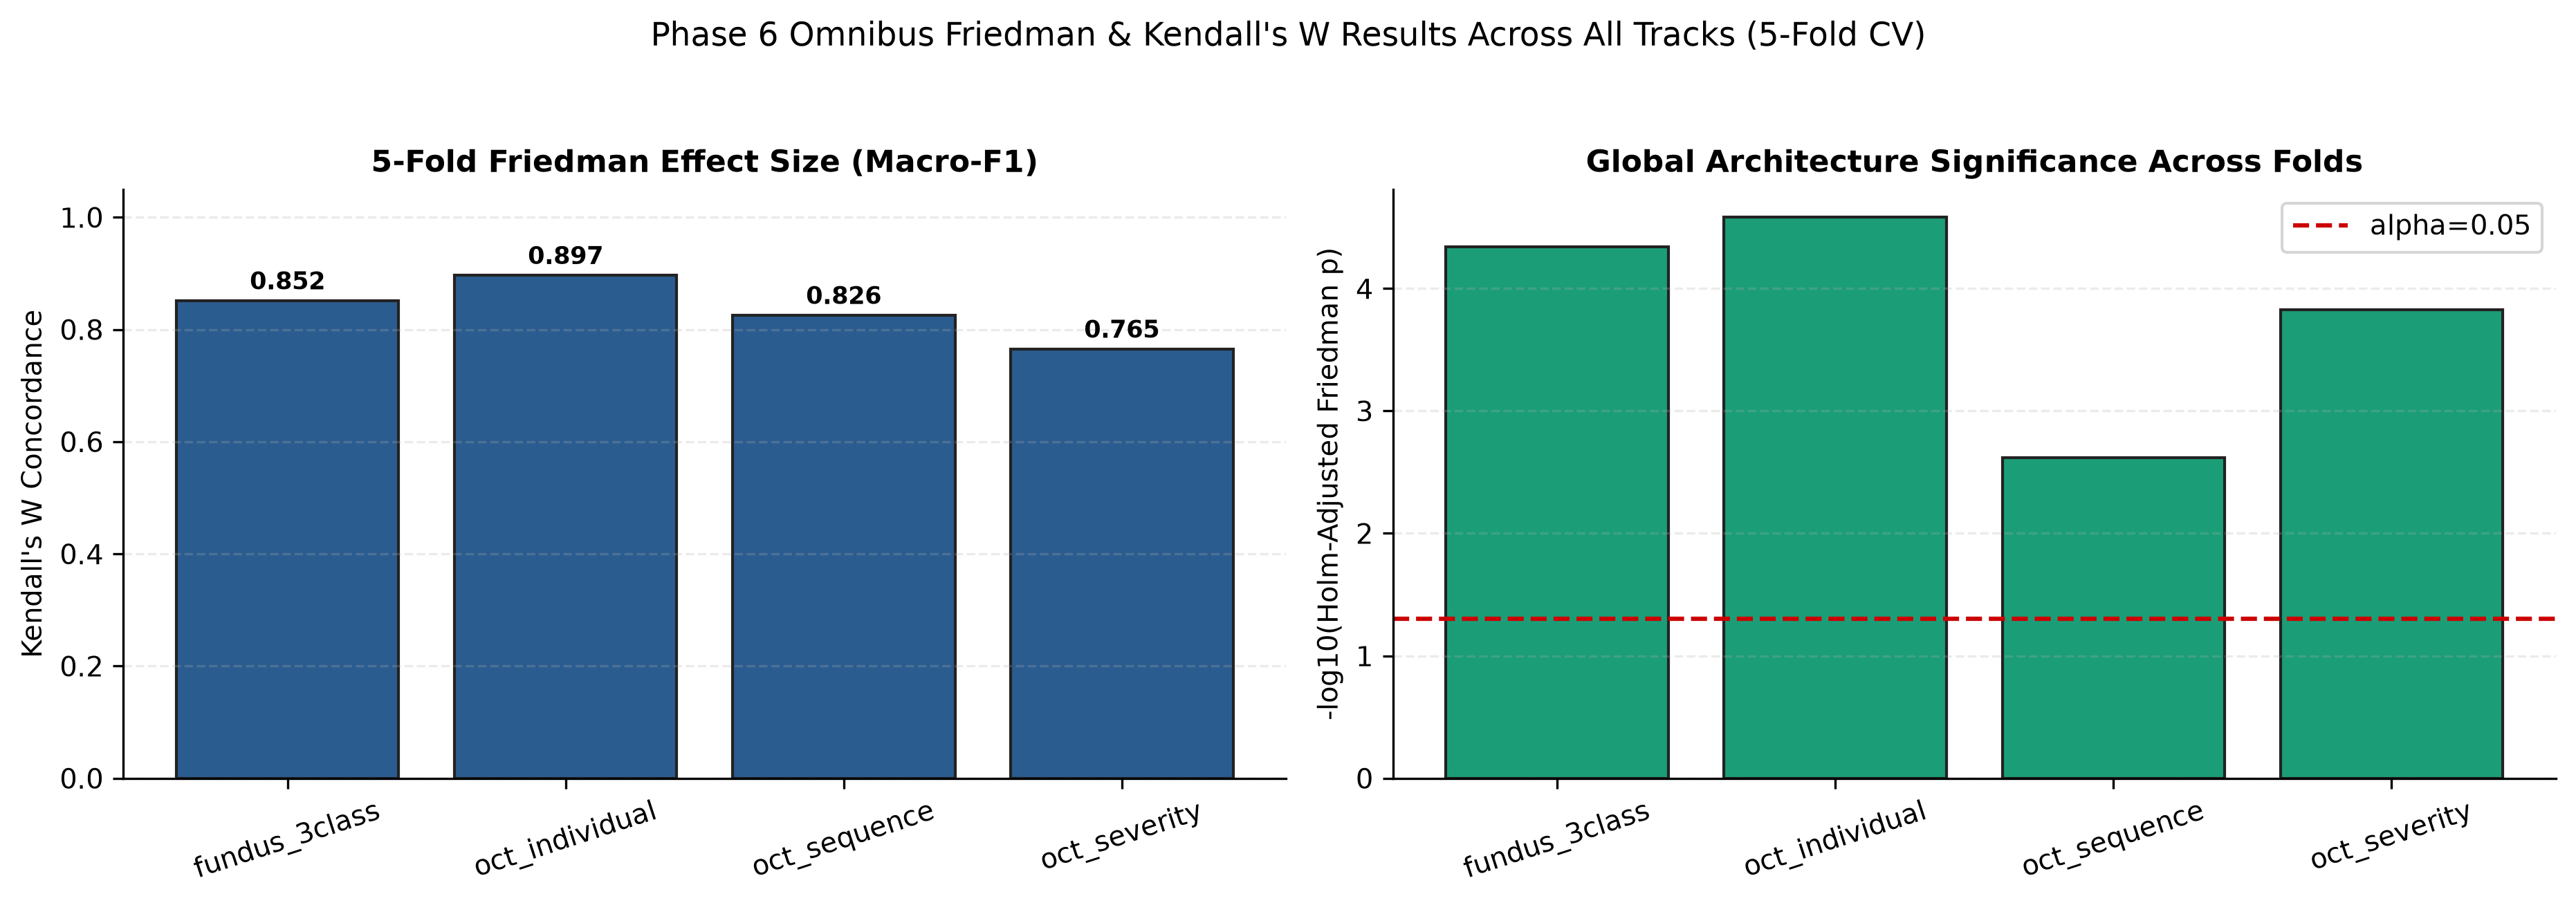

In [2]:
df_friedman = pd.read_csv(STATS_DIR / "cv_friedman_tests.csv")
display(HTML("<h4>Omnibus Friedman & Kendall's W Results Across Tracks</h4>"))
display(HTML(df_friedman.to_html(classes="table table-striped table-hover", index=False)))

display(HTML("<h5>Kendall's Concordance and Omnibus Significance Figure</h5>"))
display(Image(filename=str(FIG_DIR / "cv_stats_01_friedman_kendall.png")))


## 2. Pairwise Model Comparisons: Nadeau–Bengio vs. Naive vs. Wilcoxon

Evaluating pairwise differences against baseline and top-performing models using the Nadeau–Bengio correction and Holm FWER control.


track,metric,model_a,model_b,mean_diff,nb_t_stat,nb_p_raw,nb_p_holm,nb_significant_holm,wilcoxon_stat,wilcoxon_p_raw
fundus_3class,macro_f1,autoencoder_classifier,bilstm,0.114338,4.097648,0.014882,0.267870,False,0.0,0.0625
fundus_3class,macro_f1,autoencoder_classifier,densenet121,-0.097018,-10.844682,0.000410,0.014769,True,0.0,0.0625
fundus_3class,macro_f1,autoencoder_classifier,efficientnet_b0,-0.094862,-9.249972,0.000759,0.024243,True,0.0,0.0625
fundus_3class,macro_f1,autoencoder_classifier,efficientnet_b0_bilstm,-0.096789,-6.315497,0.003215,0.070734,False,0.0,0.0625
fundus_3class,macro_f1,autoencoder_classifier,lstm,0.116024,9.255737,0.000758,0.024243,True,0.0,0.0625
fundus_3class,macro_f1,autoencoder_classifier,mlp,0.062054,6.917514,0.002292,0.057291,False,0.0,0.0625
fundus_3class,macro_f1,autoencoder_classifier,resnet50,-0.089512,-9.807825,0.000606,0.020598,True,0.0,0.0625
fundus_3class,macro_f1,autoencoder_classifier,resnet50_bilstm,-0.098112,-13.531881,0.000173,0.006732,True,0.0,0.0625
fundus_3class,macro_f1,autoencoder_classifier,resnet50_lstm,-0.089166,-6.843132,0.002386,0.057291,False,0.0,0.0625
fundus_3class,macro_f1,bilstm,densenet121,-0.211356,-7.864668,0.001413,0.039552,True,0.0,0.0625


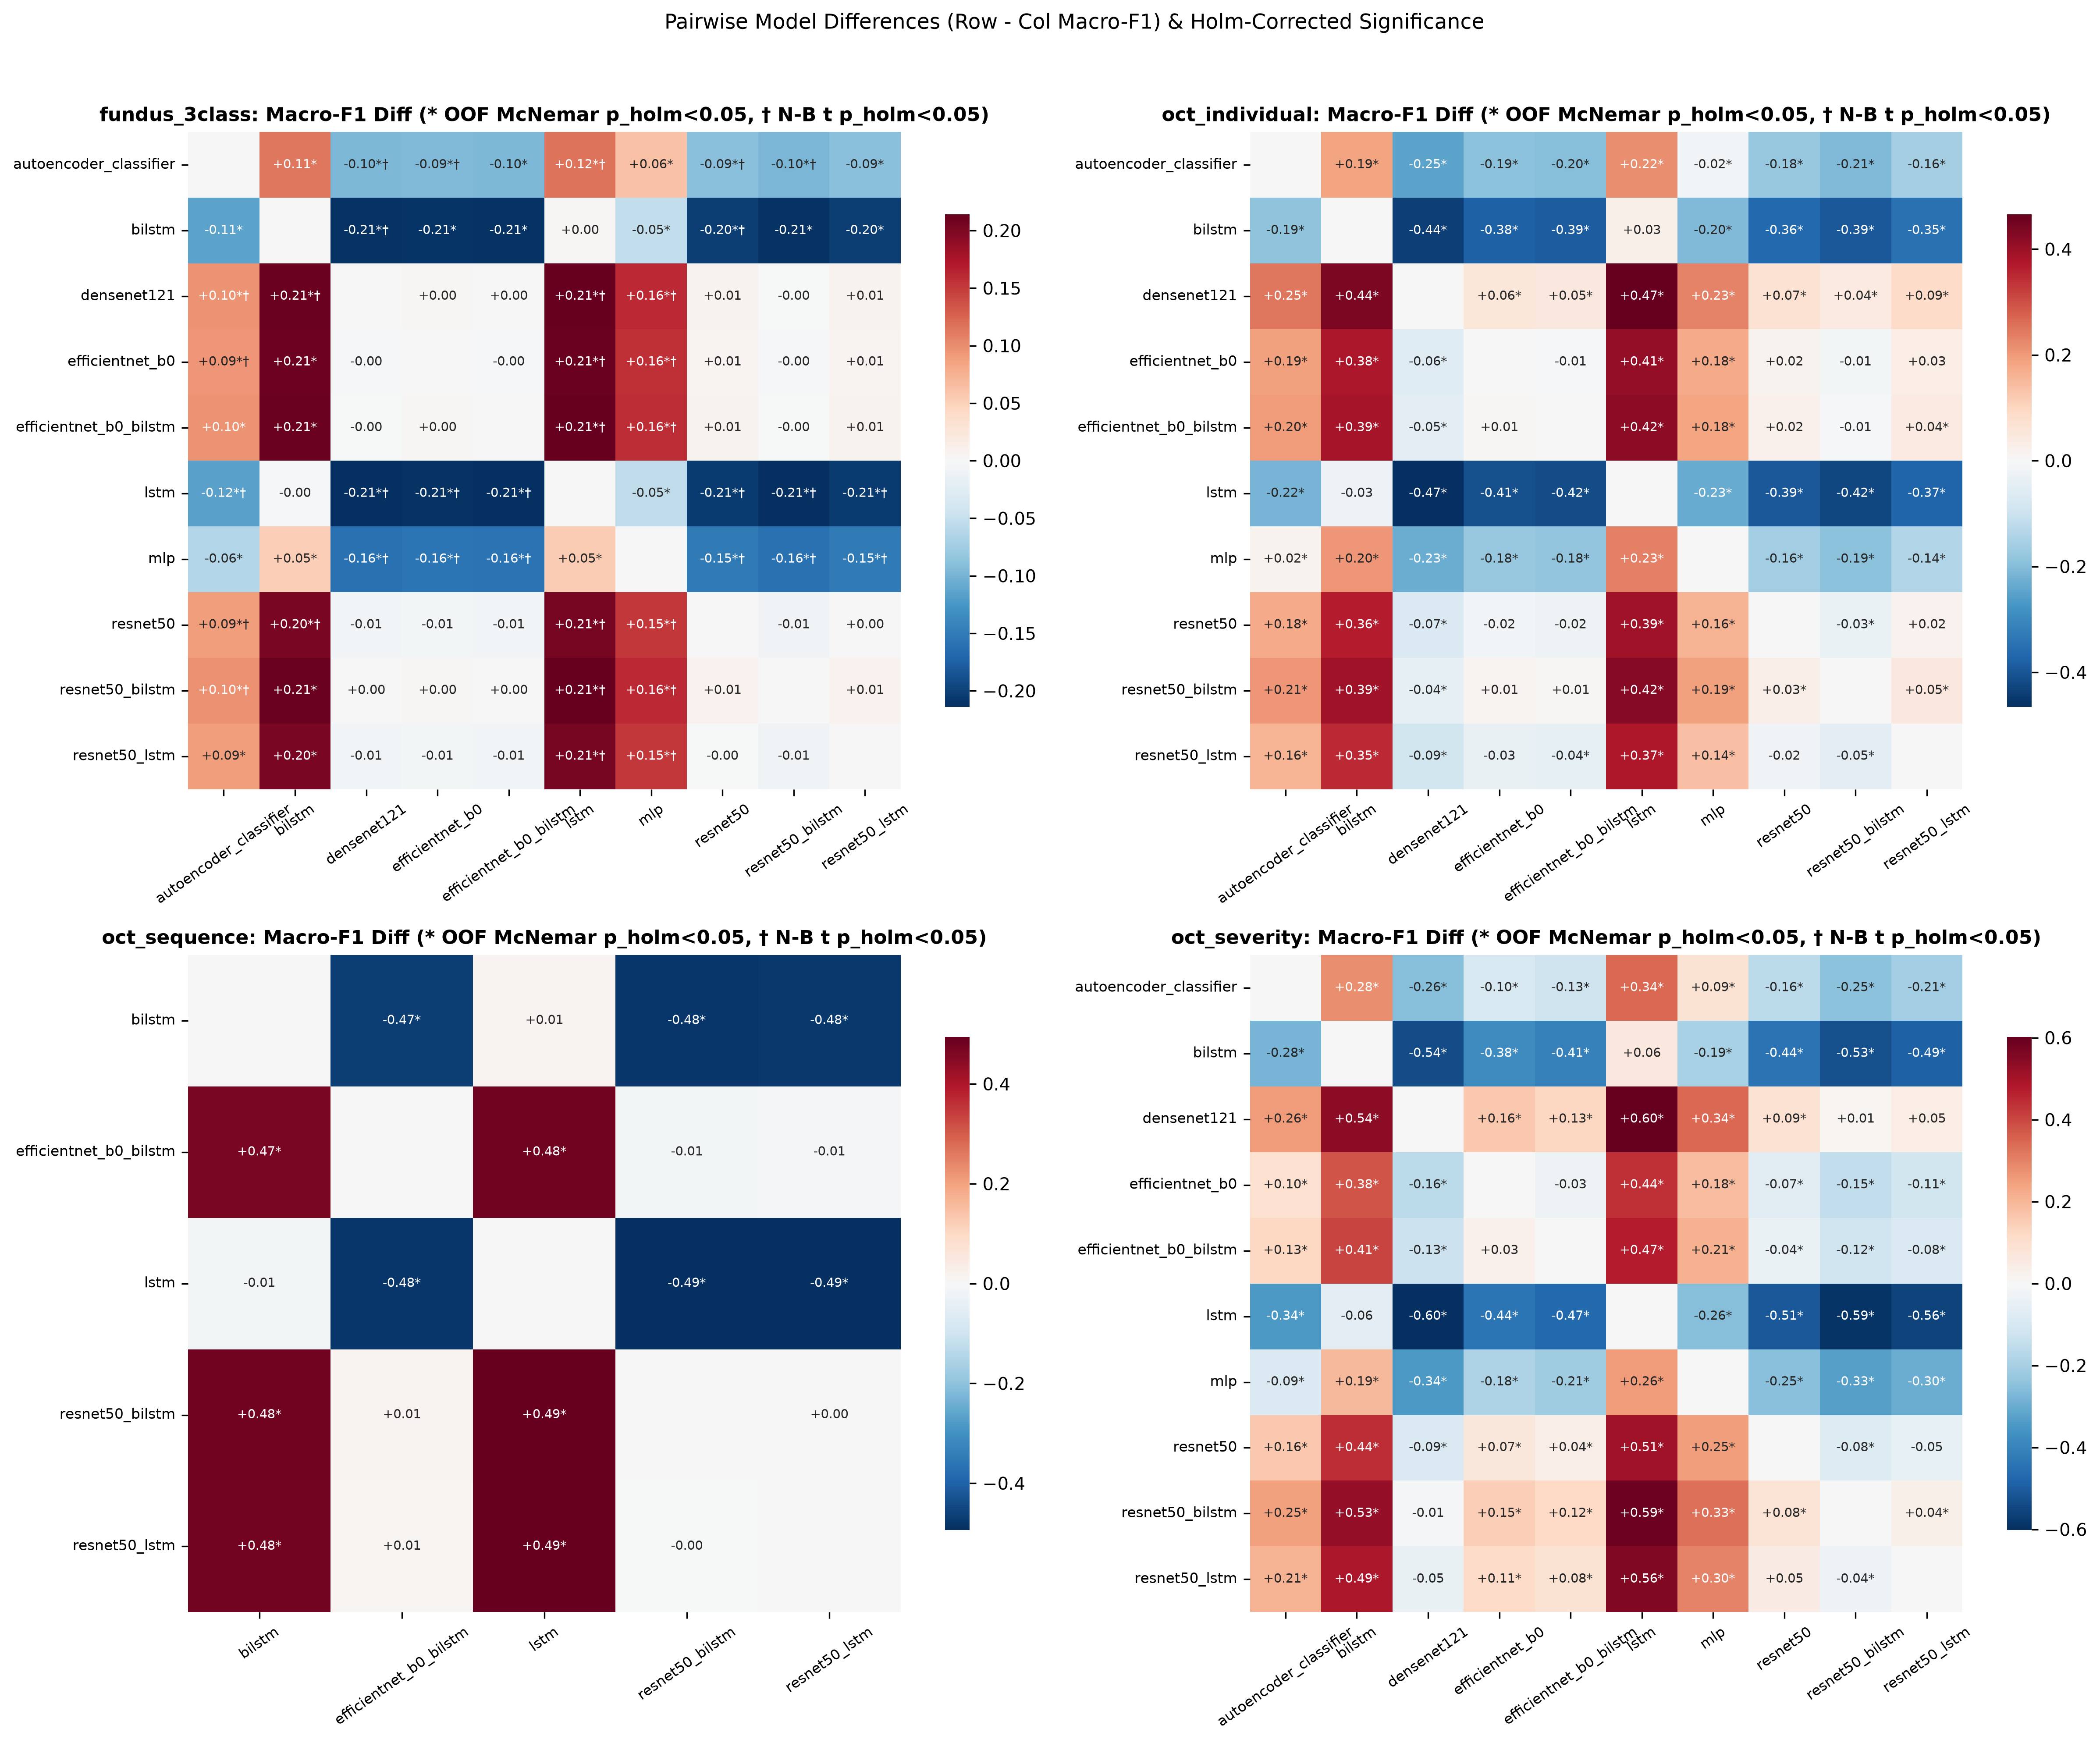

In [3]:
df_pairwise = pd.read_csv(STATS_DIR / "cv_pairwise_comparisons.csv")
display(HTML("<h4>Pairwise Comparisons Sample (Nadeau–Bengio Corrected paired t-test)</h4>"))
cols_pw = ["track", "metric", "model_a", "model_b", "mean_diff", "nb_t_stat", "nb_p_raw", "nb_p_holm", "nb_significant_holm", "wilcoxon_stat", "wilcoxon_p_raw"]
display(HTML(df_pairwise[cols_pw].head(20).to_html(classes="table table-striped table-hover", index=False)))

display(HTML("<h5>Pairwise Statistical Significance Heatmaps</h5>"))
display(Image(filename=str(FIG_DIR / "cv_stats_02_pairwise_heatmaps.png")))


## 3. Sample-Level Out-of-Fold (OOF) McNemar Contingency Tests

Testing sample-level classification disagreement on the complete pooled out-of-fold predictions.


In [4]:
df_mcnemar = pd.read_csv(STATS_DIR / "cv_oof_mcnemar_tests.csv")
display(HTML("<h4>Pooled OOF McNemar Tests Sample</h4>"))
cols_mcn = ["track", "model_a", "model_b", "n_oof_items", "b_a_only_correct", "c_b_only_correct", "statistic", "p_value", "p_adjusted_holm", "significant_holm"]
display(HTML(df_mcnemar[cols_mcn].head(15).to_html(classes="table table-striped table-hover", index=False)))


track,model_a,model_b,n_oof_items,b_a_only_correct,c_b_only_correct,statistic,p_value,p_adjusted_holm,significant_holm
fundus_3class,autoencoder_classifier,bilstm,1367,182,33,101.879070,5.901680e-24,0.000000,True
fundus_3class,autoencoder_classifier,densenet121,1367,11,127,95.833333,1.249737e-22,0.000000,True
fundus_3class,autoencoder_classifier,efficientnet_b0,1367,13,125,89.282609,3.422547e-21,0.000000,True
fundus_3class,autoencoder_classifier,efficientnet_b0_bilstm,1367,15,131,90.582192,1.774503e-21,0.000000,True
fundus_3class,autoencoder_classifier,lstm,1367,185,38,95.587444,1.415010e-22,0.000000,True
fundus_3class,autoencoder_classifier,mlp,1367,118,53,23.953216,9.870525e-07,0.000017,True
fundus_3class,autoencoder_classifier,resnet50,1367,13,120,84.481203,3.878851e-20,0.000000,True
fundus_3class,autoencoder_classifier,resnet50_bilstm,1367,14,131,92.800000,5.785515e-22,0.000000,True
fundus_3class,autoencoder_classifier,resnet50_lstm,1367,17,124,79.687943,4.384681e-19,0.000000,True
fundus_3class,bilstm,densenet121,1367,16,281,234.666667,5.723528e-53,0.000000,True


## 4. Methodological Shift: Original 5-Seed Fixed-Split vs. 5-Fold Cross-Validation

Comparing the original 5-seed fixed test-set results with the leak-free 5-fold cross-validation estimates.
- Original fixed test sets suffered from duplicate cluster leakage (Fundus) and evaluated only a single random partition of patients/slices.
- The 5-fold cross-validation evaluates 100% of the dataset out-of-fold with grouping constraints, providing realistic clinical generalization bounds.


track,model,category,macro_f1_mean,macro_f1_std,oof_macro_f1,orig_5seed_macro_f1_mean,orig_5seed_macro_f1_std,cv_minus_orig_macro_f1
fundus_3class,resnet50_bilstm,hybrid,0.962429,0.005684,0.962378,0.977852,0.008544,-0.0154
fundus_3class,densenet121,cnn,0.961335,0.009649,0.961220,0.979489,0.005369,-0.0182
fundus_3class,efficientnet_b0_bilstm,hybrid,0.961106,0.019889,0.960991,0.980630,0.010006,-0.0195
fundus_3class,efficientnet_b0,cnn,0.959179,0.016450,0.959354,0.983549,0.005512,-0.0244
fundus_3class,resnet50,cnn,0.953829,0.014680,0.953661,0.977944,0.003407,-0.0241
fundus_3class,resnet50_lstm,hybrid,0.953484,0.017039,0.953361,0.968391,0.008446,-0.0149
fundus_3class,autoencoder_classifier,baseline,0.864317,0.007597,0.864792,0.869076,0.010746,-0.0048
fundus_3class,mlp,baseline,0.802263,0.019633,0.803516,0.801774,0.017568,0.0005
fundus_3class,bilstm,rnn,0.749979,0.039664,0.750818,0.722979,0.047970,0.0270
fundus_3class,lstm,rnn,0.748293,0.019761,0.748899,0.752198,0.013223,-0.0039


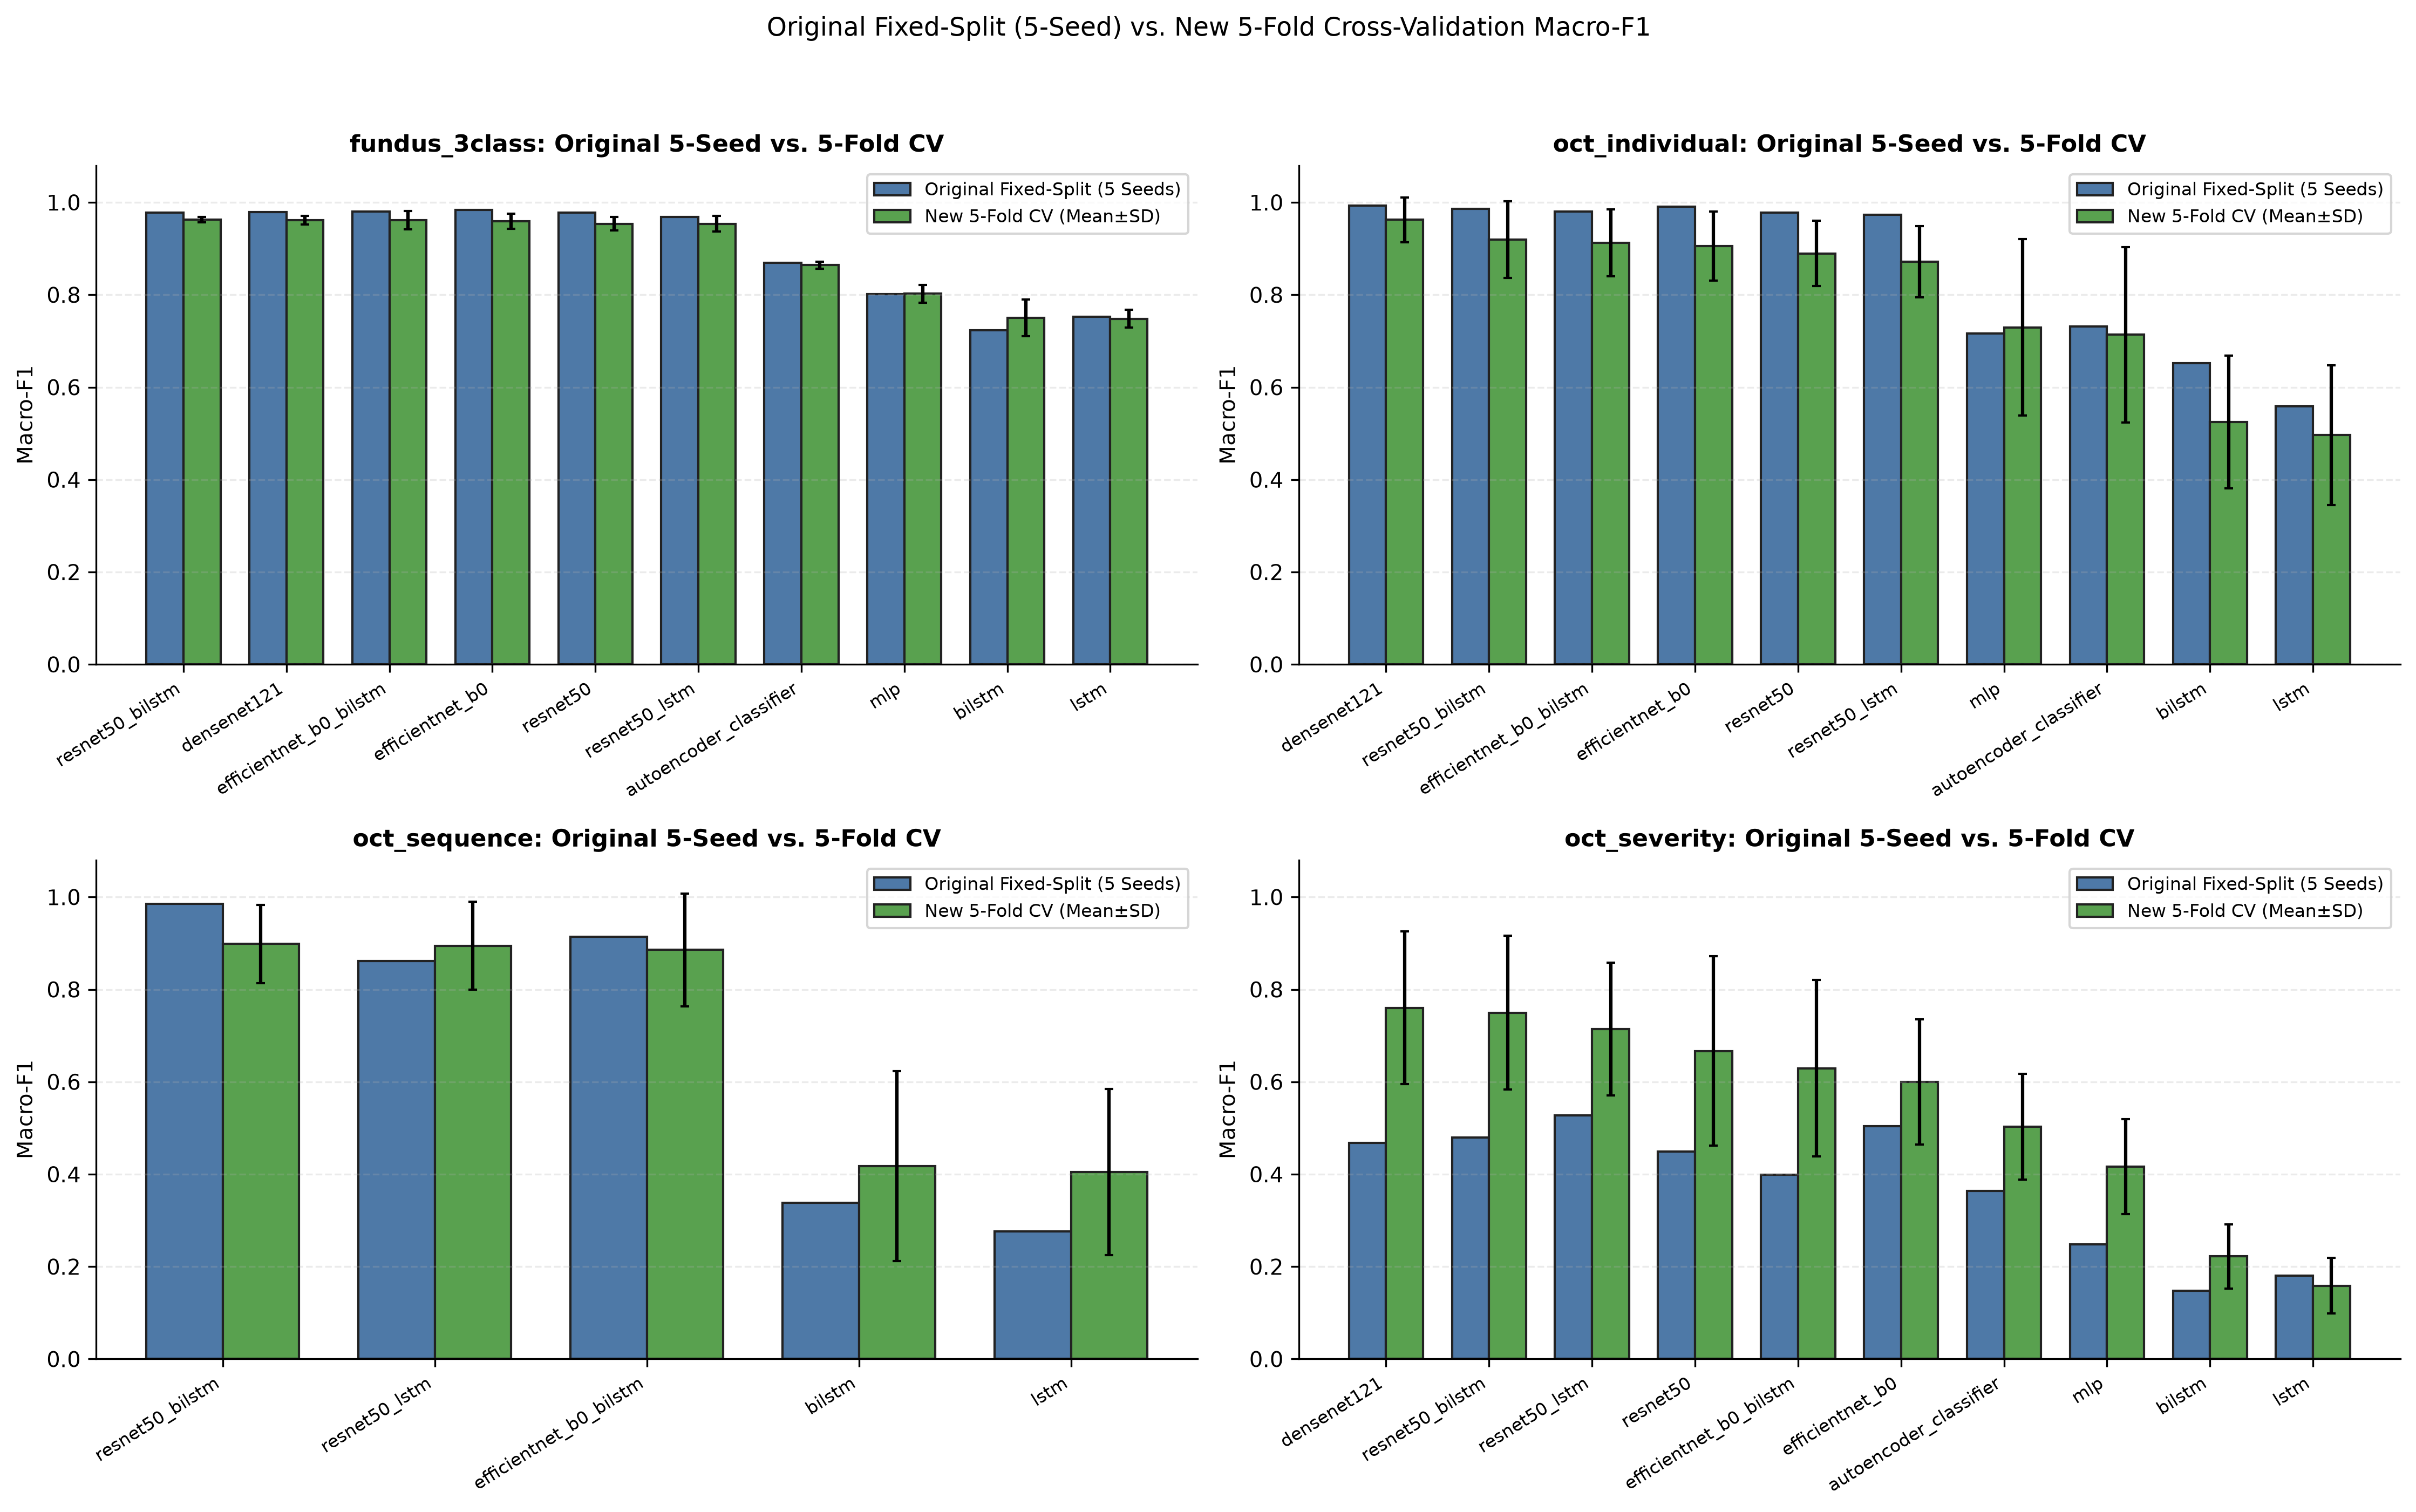

In [5]:
df_comp = pd.read_csv(STATS_DIR / "original_vs_cv_comparison.csv")
display(HTML("<h4>Original 5-Seed Fixed-Split vs. 5-Fold Cross-Validation Comparison</h4>"))
display(HTML(df_comp.to_html(classes="table table-striped table-hover", index=False)))

display(HTML("<h5>Original vs. 5-Fold CV Comparison Plot</h5>"))
display(Image(filename=str(FIG_DIR / "cv_stats_03_original_vs_cv_comparison.png")))
